In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.insert(0, '..')  # nbs/notebook_cache.py
from notebook_cache import NotebookCache

cache = NotebookCache.here(also=['00_end_to_end'])

# Verne, step 0: what it is and how shapes flow through it

The results (training, rollouts, scores): `00_end_to_end.ipynb`.

The step 0 model (`dream_robot/policies/verne/model.py`, 17/40 on T1), walked through one piece at a time: what goes in, what each piece turns it into, and what it is meant to do. No probing of _why it works_: that is `practice.ipynb`.

```-
the policy, one call:   top frame [3, 128, 128] + joints [8]  ->  next 16 actions [16, 8]
```

### setup: T1 data and the trained step 0 weights (read from step 0's cache, nothing retrains)


In [2]:
import numpy as np
import torch
from frozendict import frozendict

import dream_robot.policies.verne as verne
from dream_robot.policies.verne.data import get_batch, load_table, load_top, to_gpu

NAME = 'pick_place_cube_n100'

In [3]:
@cache
def table():
    state, action, episode = load_table(NAME)  # [N, 8], [N, 8], [N]
    return frozendict(state=state, action=action, episode=episode)

table: not cached, will compute (or read a matching result from also)


In [4]:
@cache
def images():
    return load_top(NAME)  # [N, 3, 128, 128] uint8, a few minutes the first time

images: not cached, will compute (or read a matching result from also)


In [5]:
data = table()
val = np.random.default_rng(0).permutation(100)[:10]  # as dreamzero / uwm2
rest = np.setdiff1d(np.arange(100), val)
split = frozendict(val=val, labelled=np.random.default_rng(1).choice(rest, 10, replace=False))
demos = to_gpu(images(), data['state'], data['action'], data['episode'], split['labelled'])
print({k: len(v) for k, v in split.items()}, tuple(demos.top.shape))

table: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
images: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
{'val': 10, 'labelled': 10} (21295, 3, 128, 128)


In [6]:
import dream_robot.policies.verne as verne


@cache
def train_run(steps: int, seed: int):
    return verne.train.train(demos, split['labelled'], split['val'], steps, seed=seed)

train_run: not cached, will compute (or read a matching result from also)


In [7]:
weights = train_run(20000, 0)['weights']  # training seed 0
net = verne.model.Verne().cuda().eval()
net.load_state_dict(weights)
print(f'{sum(p.numel() for p in net.parameters()) / 1e6:.2f}M params')

train_run: read from /home/rahul/Documents/codes/ml/dream-robot/cache/nbs/verne/00_end_to_end
step      0   train 2.026   val 3.142
step   1000   train 0.158   val 0.207
step   2000   train 0.073   val 0.179
step   3000   train 0.087   val 0.269
step   4000   train 0.040   val 0.177
step   5000   train 0.054   val 0.168
step   6000   train 0.057   val 0.244
step   7000   train 0.029   val 0.197
step   8000   train 0.037   val 0.189
step   9000   train 0.033   val 0.216
step  10000   train 0.038   val 0.249
step  11000   train 0.036   val 0.228
step  12000   train 0.037   val 0.183
step  13000   train 0.026   val 0.219
step  14000   train 0.045   val 0.193
step  15000   train 0.036   val 0.206
step  16000   train 0.027   val 0.201
step  17000   train 0.019   val 0.184
step  18000   train 0.020   val 0.207
step  19000   train 0.036   val 0.241
step  20000   train 0.010   val 0.246
3.66M params


### 1. one training sample

`get_batch` picks a random demo and a random step in it. A sample is what the robot saw at that step and what the expert did over the next 16 steps:

- `frame`: the top camera, pixels scaled from 0..255 to −1..1
- `state`: the 7 arm joint angles + gripper opening, each standardised (minus its mean, over its std, from the training demos), so all 8 numbers are on a similar scale
- `acts`: the expert's next 16 actions (joint targets + gripper command), standardised the same way. This is what the model learns to output.


In [8]:
b = get_batch(demos, split['labelled'], 4, np.random.default_rng(0))
for name, t in vars(b).items():
    print(f'{name:6s} {str(tuple(t.shape)):18s} range {t.min():+.2f} .. {t.max():+.2f}')

frame  (4, 3, 128, 128)   range -1.00 .. +1.00
state  (4, 8)             range -2.58 .. +1.63
acts   (4, 16, 8)         range -2.36 .. +1.75


**A batch of 4: frames [4, 3, 128, 128] in −1..1, state [4, 8] and acts [4, 16, 8] in roughly −2.5..+2 std units.** Everything the model reads and writes is on a scale of about ±2, which keeps the early layers' outputs and the loss well-behaved. `sample()` returns actions in these units too; the rollout multiplies back by `a_std` and adds `a_mean` before sending them to the robot.


In [9]:
from numpy.typing import NDArray

from dream_robot.policies.verne.data import CHUNK, Batch, Demos


@lambda f: f()
def probe():
    def get_batch(d: Demos, ids: NDArray, B: int, rng: np.random.Generator) -> Batch:
        # B samples: a random demo from `ids`, a random step of it; actions past the demo's end
        # repeat its last one, so the end of every demo is trained on too
        print(f'{ids=}')
        first = np.searchsorted(d.episode, ids)
        lens = np.searchsorted(d.episode, ids, side='right') - first
        print(f'{lens=}')
        pick = rng.integers(0, len(ids), B)
        now = first[pick] + rng.integers(0, lens[pick])  # [B]
        last = first[pick] + lens[pick] - 1
        rows = torch.tensor(np.minimum(now[:, None] + np.arange(CHUNK), last[:, None]))
        print(f'{rows.shape=}')
        print(f'rows=\n{rows}')
        return Batch(
            frame=d.top[now].float() / 127.5 - 1,
            state=(d.state[now] - d.s_mean) / d.s_std,
            acts=(d.action[rows.to(d.action.device)] - d.a_mean) / d.a_std,
        )

    b = get_batch(demos, split['labelled'], 4, np.random.default_rng(1))

ids=array([31, 42, 77,  2, 91, 45, 13, 67, 86, 25])
lens=array([212, 208, 210, 220, 213, 207, 218, 210, 208, 210])
rows.shape=torch.Size([4, 16])
rows=
tensor([[19405, 19406, 19407, 19408, 19409, 19410, 19411, 19412, 19413, 19414,
         19415, 19416, 19417, 19418, 19419, 19420],
        [ 9602,  9603,  9604,  9605,  9606,  9607,  9608,  9609,  9610,  9611,
          9612,  9613,  9614,  9615,  9616,  9617],
        [14439, 14440, 14441, 14442, 14443, 14444, 14445, 14446, 14447, 14448,
         14449, 14450, 14451, 14452, 14453, 14454],
        [ 5487,  5488,  5489,  5490,  5491,  5492,  5493,  5494,  5495,  5496,
          5497,  5497,  5497,  5497,  5497,  5497]])


### 2. the eyes, part 1: a frame becomes 65 tokens

A transformer reads a list of vectors, all the same length (here D_VIDEO = 256). `see()` makes that list:

- **cut** the 128 × 128 frame into 16 × 16-pixel squares: an 8 × 8 grid of 64 patches, each flattened to 16·16·3 = 768 numbers
- **embed**: one linear layer (`patch_in`, 768 → 256) turns each patch into a token. It learns which mixes of pixel values are worth keeping: edges, colours, the gripper's grey
- **the joints** go through their own linear layer (`state_in`, 8 → 256) and become one more token, placed first
- **add positions** (`video_pos`, one learned 256-vector per slot): attention itself has no idea which patch is where, so each slot gets a vector that says "I'm top-left", "I'm the joints token", ...


In [10]:
from einops import rearrange

patches = rearrange(b.frame, 'b c (h p) (w q) -> b (h w) (p q c)', p=16, q=16)
tokens = net.patch_in(patches)  # [B, 64, 256]
joints = net.state_in(b.state)[:, None]  # [B, 1, 256]
x = torch.cat([joints, tokens], 1) + net.video_pos  # [B, 65, 256]
print(
    f'frame {tuple(b.frame.shape)} -> patches {tuple(patches.shape)} -> tokens {tuple(tokens.shape)}'
)
print(f'joints {tuple(b.state.shape)} -> {tuple(joints.shape)};   with positions: {tuple(x.shape)}')

frame (4, 3, 128, 128) -> patches (4, 64, 768) -> tokens (4, 64, 256)
joints (4, 8) -> (4, 1, 256);   with positions: (4, 65, 256)


**Each sample is now 65 tokens of 256 numbers**: token 0 is the joints, tokens 1-64 are the patches row by row (1-8 the top row, 57-64 the bottom row). This `x` is exactly what `see()` builds before its first video layer. Every token has the same length, so the layers that follow treat the joints and the pixels alike: one list of things to relate to each other.


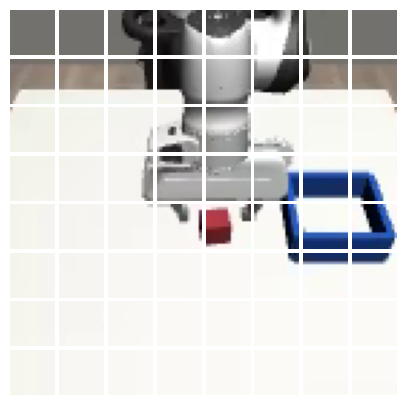

In [11]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(8, 8, figsize=(5, 5), gridspec_kw=dict(wspace=0.08, hspace=0.08))
for ax, patch in zip(axs.flat, patches[0]):
    ax.imshow(
        ((patch.view(16, 16, 3) + 1) / 2).cpu()
    )  # 768 numbers back to a 16 x 16 square, -1..1 -> 0..1
    ax.axis('off')
plt.show()

**What the 64 tokens hold:**

- **The cube spans ~2 patches** (row 5, cols 4-5), ~3% of the tokens. The grasp depends on those two plus the 3-4 patches with the gripper's fingers.
- **About half the patches are empty table**, the top row is background. Each still gets a full token and the same attention.
- **Patch edges cut through objects**: the gripper is split over ~10 patches, the cube straddles a border. Only the learned position vectors tell the model which patches are neighbours. (Verne patches VAE latents instead: each latent cell has already summarised its neighbourhood with convolutions.)


In [12]:
@lambda f: f()
def probe():
    print(f'{128 / 16=}')
    print(f'{16*16*3=}')

128 / 16=8.0
16*16*3=768


### 2. the eyes, part 2: four video layers, and what they save

Each video layer (`Block`, pre-norm transformer) updates the 65 tokens in two moves:

- **attention**: every token makes a query q ("what am I looking for"), a key k ("what I am about") and a value v ("what I pass on"). Each token takes a weighted mix of all 65 values, weighted by how well its query matches each key. 4 heads do this in parallel, each with 32-number q/k/v, so a patch can look for different things at once (the gripper, the cube, the joints). This is how a patch's token comes to carry information about _other_ patches.
- **MLP**: each token then goes through a small 2-layer network on its own (256 → 1024 → 256).

Both moves are added onto the token (residual), so a layer refines the tokens rather than replacing them. `Block` is split into `qkv_of` and `finish` so that `see()` can **keep each layer's k and v**: that pair is what the action side will read.


In [13]:
x = torch.cat([net.state_in(b.state)[:, None], net.patch_in(patches)], 1) + net.video_pos
block = net.video[0]
q, k, v = block.qkv_of(x)  # each [B, heads, tokens, head_dim]
x1 = block.finish(x, q, k, v)
print(f'in {tuple(x.shape)} -> q, k, v {tuple(q.shape)} each -> out {tuple(x1.shape)}')

in (4, 65, 256) -> q, k, v (4, 4, 65, 32) each -> out (4, 65, 256)


In [14]:
kvs = net.see(b.frame, b.state)  # all 4 layers
print(f'{len(kvs)} layers, each saves k {tuple(kvs[0][0].shape)} and v {tuple(kvs[0][1].shape)}')
print(f'layer 0 keys equal the ones above: {torch.allclose(kvs[0][0], k)}')

4 layers, each saves k (4, 4, 65, 32) and v (4, 4, 65, 32)
layer 0 keys equal the ones above: True


**A layer keeps the shape, [B, 65, 256] in and out; what it saves is 4 heads × 65 tokens × 32 numbers, twice (k and v), per layer.** `see()` returns those 4 (k, v) pairs and nothing else: the eyes' final tokens are never used directly. That's the whole interface between the two halves, and since nothing in it depends on the actions, it is computed once per chunk.


In [15]:
@lambda f: f()
def probe():
    print(f'{4*32=}')
    print(f'{3*4*32=}')
    qkv_res = block.qkv(block.norm1(x))
    print(f'{x.shape=}')
    print(f'{qkv_res.shape=}')

4*32=128
3*4*32=384
x.shape=torch.Size([4, 65, 256])
qkv_res.shape=torch.Size([4, 65, 384])


### 3. the hands: from a noisy chunk to a velocity

The action side never sees pixels. Its input is a **noisy guess** of the 16 actions, plus how noisy it is (τ: 0 = pure noise, 1 = the real chunk). Its output is a **velocity**: the direction, per number, that moves the guess toward a real chunk. Sampling (section 4) follows that direction step by step.

- **16 action tokens**: each row of the chunk (8 numbers) → `action_in` (8 → 128), plus a learned position per row (`action_pos`), plus the noise level τ through a tiny MLP (`time_in`, added to every row).
- **4 action layers, paired with the 4 video layers**: in action layer i, the 16 action tokens attend over **65 video keys from video layer i plus their own 16** = 81 keys. The video keys tell a row what the scene looks like; the action keys let the 16 rows agree on one smooth motion. The video tokens never look back at the actions.
- **out**: `action_out` (128 → 8) per row → [B, 16, 8].

The hands are narrower (128 wide vs the eyes' 256) but use the same 4 heads × 32, so their q can be matched against the eyes' k.


In [16]:
noise = torch.randn_like(b.acts)  # [B, 16, 8]
tau = torch.full((len(b.acts),), 0.5, device='cuda')  # halfway from noise to the real chunk
x_noisy = (1 - tau[:, None, None]) * noise + tau[:, None, None] * b.acts
y = net.action_in(x_noisy) + net.action_pos + net.time_in(tau[:, None])[:, None]
print(f'noisy chunk {tuple(x_noisy.shape)} -> action tokens {tuple(y.shape)}')

noisy chunk (4, 16, 8) -> action tokens (4, 16, 128)


In [17]:
@lambda f: f()
def probe():
    print(f'{b.acts.shape=}')
    print(f'{tau.shape=}')
    print(f'{net.time_in(tau[:, None])[:, None].shape=}')

b.acts.shape=torch.Size([4, 16, 8])
tau.shape=torch.Size([4])
net.time_in(tau[:, None])[:, None].shape=torch.Size([4, 1, 128])


In [18]:
block = net.action[0]
q, k, v = block.qkv_of(y)
k_all, v_all = torch.cat([kvs[0][0], k], 2), torch.cat([kvs[0][1], v], 2)  # video layer 0's + own
print(
    f'action q {tuple(q.shape)}, keys {tuple(kvs[0][0].shape)} video + {tuple(k.shape)} own '
    f'-> {tuple(k_all.shape)}'
)
print(f'after the layer: {tuple(block.finish(y, q, k_all, v_all).shape)}')

action q (4, 4, 16, 32), keys (4, 4, 65, 32) video + (4, 4, 16, 32) own -> (4, 4, 81, 32)
after the layer: (4, 16, 128)


In [19]:
velocity = net.velocity(kvs, x_noisy, tau)  # all 4 layers + action_out
print(f'velocity {tuple(velocity.shape)}: one number per action number, same shape as the chunk')

velocity (4, 16, 8): one number per action number, same shape as the chunk


**16 action queries against 81 keys (65 from the eyes, 16 their own), out comes a velocity [B, 16, 8], the chunk's own shape.** Each action layer reads a different video layer: layer 0 sees keys built from nearly raw patches, layer 3 sees keys after four rounds of mixing among the patches. The output says, for every one of the 128 action numbers, which way and how fast to move the noisy guess.


### 4. training: flow matching (`loss`)

Pick noise ε and a real chunk a (both [16, 8]), and a random τ in 0..1. The training input is a point on the straight line between them; the target is the line's direction:

```-
x_τ = (1 − τ)·ε + τ·a          τ = 0: pure noise,  τ = 1: the real chunk
dx_τ/dτ = a − ε                the same direction at every τ on this line
loss = mean( (velocity(x_τ, τ) − (a − ε))² )
```

The model never sees a and ε separately, only the mixture x*τ (plus the frame and joints). So it can't know the exact ε; the best it can do is predict the *average* direction a − ε over every (noise, chunk) pair that passes through x*τ. Following that average direction from noise lands on a plausible chunk for this frame. The loss is ~2 for an untrained net: velocities are about the size of a − ε, and both are ~1 std per number.


In [20]:
torch.manual_seed(0)
untrained = verne.model.Verne().cuda().eval()
with torch.no_grad():
    print(f'loss, trained step 0 model: {verne.model.loss(net, b.frame, b.state, b.acts):.3f}')
    print(
        f'loss, untrained:            {verne.model.loss(untrained, b.frame, b.state, b.acts):.3f}'
    )

loss, trained step 0 model: 0.049
loss, untrained:            2.400


**Loss 0.049 trained vs 2.40 untrained.** Untrained, the velocity is unrelated to a − ε, whose numbers are each about √2 std (difference of two ~1-std things), so the squared error is ~2. Trained, it predicts the direction to within a few hundredths. These 4 samples are from the 10 training demos, so this is the fit, not generalisation (held-out ended at 0.25).


### 4b. sampling (`sample`): 10 small steps from noise to a chunk

```-
x ← ε (pure noise),  τ = 0
repeat 10 times:  x ← x + velocity(x, τ) / 10,   τ ← τ + 0.1
```

`see()` runs once before the loop; each of the 10 steps runs only the action side against the saved keys and values. The result is in std units; the rollout converts back with `a_std`, `a_mean`.


In [21]:
torch.manual_seed(0)
chunk = verne.model.sample(net, b.frame[:1], b.state[:1])  # sample 0 of the batch
err = (chunk[0] - b.acts[0]).abs().mean(0)  # [8], per action number
print(
    f'sampled {tuple(chunk.shape)};  mean |sampled - expert| per number (std units): '
    f'{[round(e, 2) for e in err.tolist()]}'
)

sampled (1, 16, 8);  mean |sampled - expert| per number (std units): [0.05, 0.05, 0.02, 0.06, 0.07, 0.05, 0.02, 0.16]


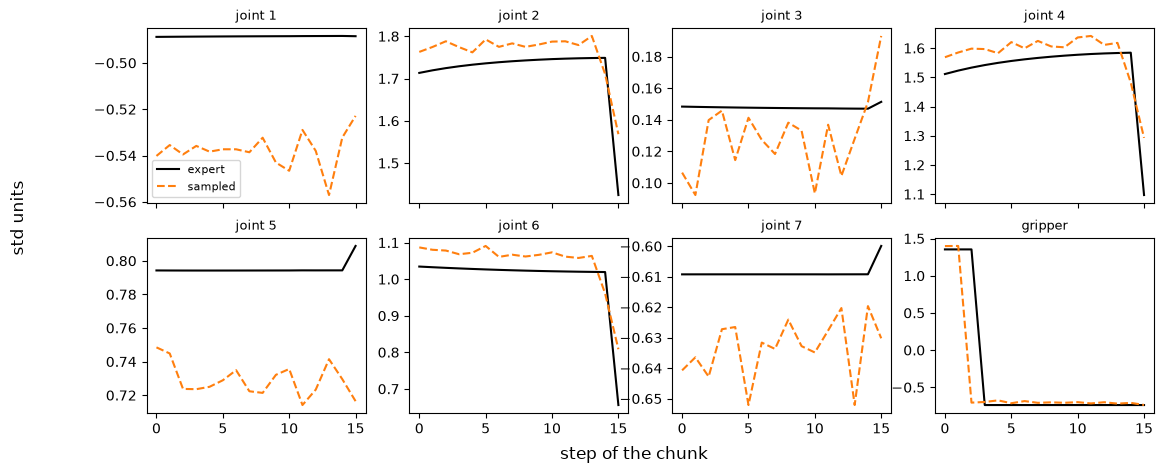

In [22]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(13, 5), sharex=True)
for i, ax in enumerate(axs.flat):
    ax.plot(b.acts[0, :, i].cpu(), 'k', label='expert')
    ax.plot(chunk[0, :, i].cpu(), 'C1--', label='sampled')
    ax.set_title(f'joint {i + 1}' if i < 7 else 'gripper', fontsize=9)
axs[0, 0].legend(fontsize=8)
fig.supxlabel('step of the chunk')
fig.supylabel('std units')
plt.show()

**The sampled chunk lies on the expert's: mean error 0.02-0.07 std per joint, 0.16 for the gripper.** Same caveat: a training sample. The gripper is the loosest, plausibly because its command switches between open and closed rather than gliding, and the exact step of a switch is hard to place (not checked on this sample). From here the rollout un-standardises the chunk and plays 8 or 16 of its rows on the robot.


### 5. the policy in the sim: one rollout

Everything above, wrapped into a control loop on T1 (seed 1000, the first eval seed):

- read the top frame and the 8 joint/gripper numbers from the sim; scale them as in training (pixels to −1..1, joints standardised)
- `sample()` a chunk of 16 actions, un-standardise it (× `a_std` + `a_mean`), clip the gripper command to 0..1
- **play the first 8 rows open-loop** (no new look in between), then look again and sample a new chunk. The robot runs at 30 Hz, so the model is consulted every 8 / 30 ≈ 0.27 s
- stop at success, failure or 600 steps (20 s)


In [23]:
from dream_robot.policies.verne import rollouts

env = rollouts.make_env(wide=False)

In [24]:
import imageio
from IPython.display import Markdown, display


def film(seed: int) -> bool:
    # one T1 rollout of the step 0 model, replanning every 8; writes [top | wrist] to scratch/
    torch.manual_seed(seed)
    obs, plan, frames, calls = env.reset(seed=seed), [], [], 0
    for step in range(600):
        frames.append(np.concatenate([obs.images['top'], obs.images['wrist']], axis=1))
        if not plan:  # frame + joints scaled as in training -> 16 raw actions, gripper clipped 0..1
            plan, calls = list(rollouts.act(net, demos, obs)[:8]), calls + 1
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    outcome = 'success' if r.success else str(r.failure_mode)
    path = f'../../scratch/rough_rollout_seed{seed}_{outcome}.mp4'
    imageio.mimsave(path, frames, fps=30)
    display(
        Markdown(
            f'seed {seed}, {outcome}: {step + 1} steps, {calls} model calls → [{path.split("/")[-1]}]({path})'
        )
    )
    return r.success


film(1000)

seed 1000, no_grasp: 600 steps, 75 model calls → [rough_rollout_seed1000_no_grasp.mp4](../../scratch/rough_rollout_seed1000_no_grasp.mp4)

False

**Seed 1000: no_grasp after 600 steps and 75 model calls** (also a failure in step 0's sweeps). In the film [top | wrist], the arm comes down by the cube early, misses, rises, and then hovers above the cube for the rest of the episode with the cube in the bottom of the wrist view, never descending again. 75 calls × 8 actions = 600 steps: the loop itself works, the chunks just stop leading anywhere. Step 0 (training seed 0) succeeds on 24 of 50 eval seeds this way (seed 1003 is one); 54/150 over three training seeds, see `00_end_to_end.ipynb`.


In [25]:
for seed in range(1001, 1020):  # the first seed that succeeds
    if film(seed):
        break

seed 1001, success: 215 steps, 27 model calls → [rough_rollout_seed1001_success.mp4](../../scratch/rough_rollout_seed1001_success.mp4)

**Seed 1001: success in 215 steps, 27 model calls**, about the expert's pace (its T1 demos take ~200-220 steps). Same loop and model as seed 1000; here the first descent lands on the cube and every later chunk follows through: lift, carry, release.
